**Watershed** — це алгоритм сегментації зображень, який розділяє зображення на області, використовуючи ідею затоплення рельєфу.
Він особливо корисний, коли кілька об'єктів торкаються один одного і звичайна бінаризація або пошук контурів не можуть визначити, де закінчується один об'єкт і починається інший.

Наприклад, якщо на зображенні лежать 10 монет, які частково перекриваються, звичайна бінаризація може побачити лише одну велику білу область.
 Watershed допомагає розділити її на окремі монети. Саме для такого сценарію OpenCV пропонує офіційний приклад із Distance Transform і Watershed.

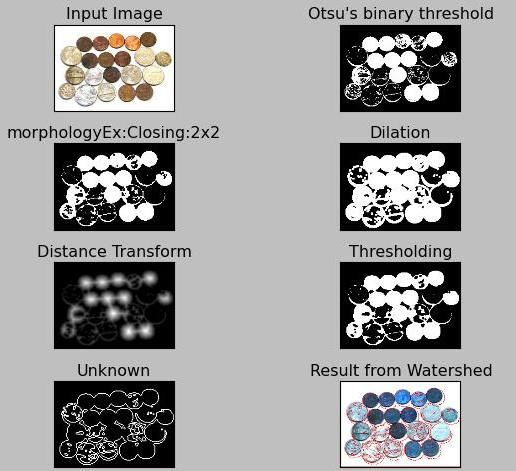

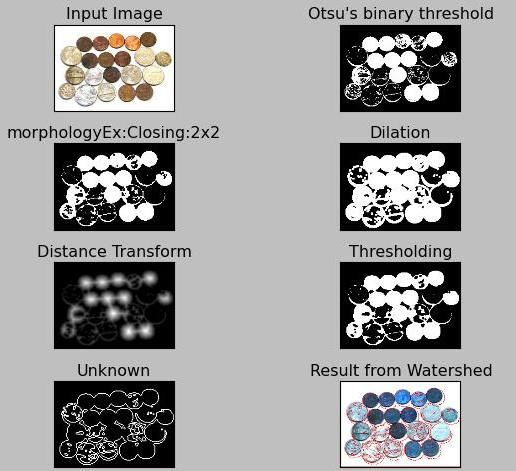

Уявімо, що ми перетворили зображення на тривимірний рельєф.
- Темні ділянки можуть відповідати низинам.
- Світлі ділянки — височинам.
- Градієнт яскравості визначає, наскільки різко змінюється поверхня.
Тепер починаємо наливати воду в низини. Вода поступово заповнює сусідні ділянки. Коли вода з різних басейнів зустрічається, між ними будується бар'єр. Ці бар'єри й утворюють межі сегментації.

* **Рельєф** - Алгоритм використовує перепади інтенсивності зображення, щоб визначити, де проходять межі між областями.

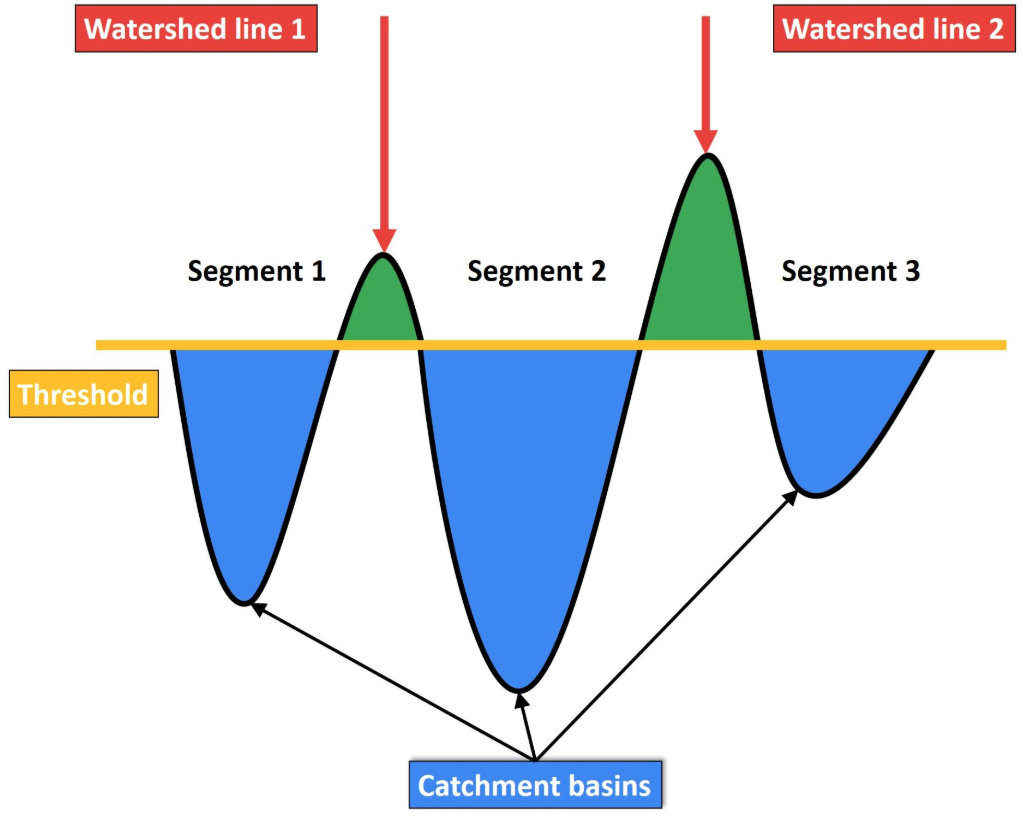

* **Затоплення** - регіони ростуть від заданих початкових точок — маркерів.
* **Межі** - там де регіони зустрічаються алгоритм формує межі


Припустимо, що дві монети торкаються одна одної. Після бінаризації отримуємо одну спільну область.

### Крок 1. Бінарна маска

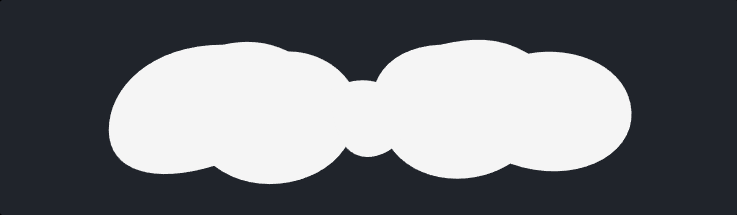

Обидва об'єкти можуть утворювати одну зв'язну білу область.

### Крок 2. Distance Transform та маркери

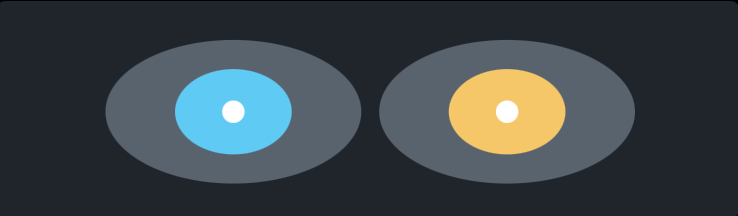

Піки відстані до фону допомагають визначити внутрішні області кожної монети.

### Крок 3. Результат Watershed

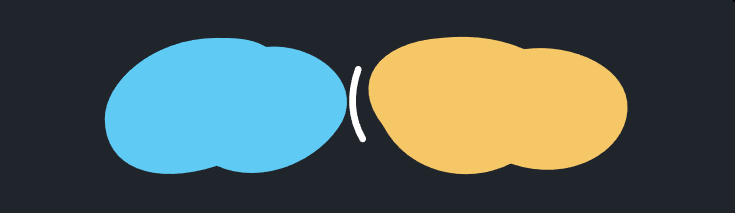

Різні мітки задають різні сегменти, а біла лінія показує умовну межу між ними.

Для білої області монети:
- на краю відстань близька до нуля;
- усередині вона зростає;
- у центрі зазвичай утворюється максимум.
Якщо монети з'єднані вузькою ділянкою, карта відстаней часто містить два окремі піки. Після порогової обробки цих піків ми отримуємо два маркери, від яких Watershed розділяє спільну область.

Офіційний приклад OpenCV використовує саме цей підхід: Distance Transform → поріг → маркери → Watershed.

    **Обмеження**: два піки не завжди означають два об'єкти. Якщо об'єкт має складну форму, кілька виступів або нерівну поверхню, він може породжувати декілька піків.
     Тоді алгоритм може розділити один об'єкт на кілька частин.

| Метод | Переваги | Недоліки |
| :--- | :--- | :--- |
| **Thresholding** | Дуже простий і швидкий | Не розділяє об'єкти, які торкаються |
| **Contours** | Дає геометричні межі бінарних областей | Якщо об'єкти злиті в одну область, знайде один зовнішній контур |
| **Watershed** | Розділяє суміжні об'єкти; не потребує навчання | Чутливий до маркерів і попередньої обробки |
| **Canny** | Добре виявляє локальні краї | Не формує готові семантичні сегменти |
| **GrabCut** | Може виділяти об'єкт за приблизною областю чи маскою | Потребує початкової ініціалізації; орієнтований на foreground/background |
| **CNN-сегментація** | Може навчитися розпізнавати об'єкти за складними ознаками | Потребує даних, обчислень і навчання |


### Типові проблеми та способи їх усунення

| Симптом | Ймовірна причина | Що спробувати |
| :--- | :--- | :--- |
| **Один об'єкт розділився на багато** | Зайві маркери | Збільшити поріг `Distance Transform` або об'єднати близькі маркери |
| **Два об'єкти залишилися одним сегментом** | Один маркер на двох об'єктах | Знайти окремі локальні максимуми |
| **Контур сильно пошкоджений** | Надмірна морфологія | Зменшити ядро або кількість ітерацій |
| **Багато шумових сегментів** | Шумна бінарна маска | Згладити зображення та видалити дрібні компоненти |
| **Межі проходять не там** | Невдалі маркери або слабкий контраст | Покращити початкову маску та контраст |
| **Результат не відділяє фон** | Неправильно побудовані маркери | Перевірити `sure_bg`, `sure_fg` та `unknown` |


In [1]:
from dataclasses import dataclass

import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt
from core.entities.constants import Paths as p

In [2]:
IMAGE_PATH = p.IMAGE_ASSETS / "tesla.jpg"


img = cv.imread(IMAGE_PATH)

if img is None:
    raise ValueError("Could not read the image.")

img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

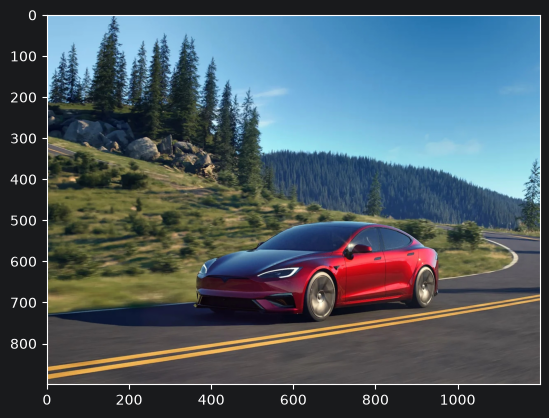

In [3]:
plt.figure()
plt.imshow(img_rgb)

In [4]:
morph_operations = [None, cv.MORPH_DILATE, cv.MORPH_CLOSE, cv.MORPH_ERODE, cv.MORPH_OPEN]
morph_titles = ["none", "dilate", "close", "erode", "open"]

dist_types = [cv.DIST_L1, cv.DIST_L2]
dist_types_titles = ["DIST_L1", "DIST_L2"]

In [5]:
@dataclass(frozen=True)
class PreprocessBarTitles:
    WINDOW_NAME: str = "Preprocessing"
    THRESHOLD: str = "threshold"
    MORPH_OPERATION: str = "morphology_operation"
    KERNEL_SIZE: str = "kernel_size"


@dataclass(frozen=True)
class DistTransformdBarTitles:
    WINDOW_NAME: str = "Distance Transform"
    MASK_SIZE: str = "mask_size"
    DIST_TYPE: str = "dist_type"

@dataclass(frozen=True)
class LabelsBarTitles:
    WINDOW_NAME: str = "Labels"
    DIST_THRESHOLD: str = "dist_threshold"
    CONNECTIVITY: str = "connectivity x4"

In [6]:
def put_text(text: str, src: np.ndarray) -> None:
    cv.putText(src, text, (5, 20), cv.FONT_HERSHEY_SIMPLEX, fontScale=0.5, color=(255, 255, 255), thickness=5)

In [7]:
def callback(value: int) -> None:
    pass

In [8]:
########################################
# PREPROCESSING WINDOW
########################################

cv.namedWindow(PreprocessBarTitles.WINDOW_NAME)

cv.createTrackbar(PreprocessBarTitles.THRESHOLD, PreprocessBarTitles.WINDOW_NAME, 100, 255, callback)
cv.createTrackbar(PreprocessBarTitles.MORPH_OPERATION, PreprocessBarTitles.WINDOW_NAME, 1, len(morph_operations) - 1, callback)
cv.createTrackbar(PreprocessBarTitles.KERNEL_SIZE, PreprocessBarTitles.WINDOW_NAME, 3, 21, callback)

########################################
# DISTANCE TRANSFORM WINDOW
########################################

cv.namedWindow(DistTransformdBarTitles.WINDOW_NAME)

cv.createTrackbar(DistTransformdBarTitles.MASK_SIZE, DistTransformdBarTitles.WINDOW_NAME, 3, 5, callback)
cv.setTrackbarMin(DistTransformdBarTitles.MASK_SIZE, DistTransformdBarTitles.WINDOW_NAME, 3)

cv.createTrackbar(DistTransformdBarTitles.DIST_TYPE, DistTransformdBarTitles.WINDOW_NAME, 1, len(dist_types) - 1, callback)

########################################
# CCL WINDOW
########################################

cv.namedWindow(LabelsBarTitles.WINDOW_NAME)

cv.createTrackbar(LabelsBarTitles.DIST_THRESHOLD, LabelsBarTitles.WINDOW_NAME, 0, 255, callback)

cv.createTrackbar(LabelsBarTitles.CONNECTIVITY, LabelsBarTitles.WINDOW_NAME, 1, 2, callback)
cv.setTrackbarMin(LabelsBarTitles.CONNECTIVITY, LabelsBarTitles.WINDOW_NAME, 1)


while True:
    if cv.waitKey(1) == ord("q"):
        break

    ####################
    # PREPROCESSING
    ####################
    threshold_value = cv.getTrackbarPos(PreprocessBarTitles.THRESHOLD, PreprocessBarTitles.WINDOW_NAME)
    img_threshold = cv.threshold(img_gray, threshold_value, 255, cv.THRESH_BINARY_INV)[1]

    morph_operation_idx = cv.getTrackbarPos(PreprocessBarTitles.MORPH_OPERATION, PreprocessBarTitles.WINDOW_NAME)

    if morph_operation_idx != 0:
        morph_operation = morph_operations[morph_operation_idx]
        kernel_size = cv.getTrackbarPos(PreprocessBarTitles.KERNEL_SIZE, PreprocessBarTitles.WINDOW_NAME)
        kernel = np.ones((kernel_size, kernel_size), np.uint8)
        img_threshold = cv.morphologyEx(img_threshold, morph_operation, kernel)
    else:
        kernel_size = "unused"

    ########################################
    # DISTANCE TRANSFORM
    #######################################
    mask_size = cv.getTrackbarPos(DistTransformdBarTitles.MASK_SIZE, DistTransformdBarTitles.WINDOW_NAME)

    if mask_size % 2 == 0:
        mask_size = mask_size + 1
        cv.setTrackbarPos(DistTransformdBarTitles.MASK_SIZE, DistTransformdBarTitles.WINDOW_NAME, mask_size)

    dist_type_idx = cv.getTrackbarPos(DistTransformdBarTitles.DIST_TYPE, DistTransformdBarTitles.WINDOW_NAME)
    dist_type = dist_types[dist_type_idx]
    dist_transform = cv.distanceTransform(img_threshold, dist_type, mask_size)

    ########################################
    # CCL
    ########################################

    dist_threshold_val = cv.getTrackbarPos(LabelsBarTitles.DIST_THRESHOLD, LabelsBarTitles.WINDOW_NAME)
    dist_threshold = cv.threshold(dist_transform, dist_threshold_val, 255, cv.THRESH_BINARY)[1]
    dist_threshold = np.uint8(dist_threshold)

    connectivity = cv.getTrackbarPos(LabelsBarTitles.CONNECTIVITY, LabelsBarTitles.WINDOW_NAME) * 4

    labels = cv.connectedComponents(dist_threshold, connectivity=connectivity)[1]

    ########################################
    # WATERSHED
    ########################################
     # 1. Находим гарантированный фон (расширяем бинарное изображение маски шариков)
    # Пиксели внутри шариков гарантированно не являются фоном
    kernel_bg = np.ones((3, 3), np.uint8)
    sure_bg = cv.dilate(img_threshold, kernel_bg, iterations=2)

    # 2. Находим неизвестную область (разница между расширенным фоном и уверенными центрами)
    # Именно в этой зоне watershed будет строить точные границы
    sure_foreground = dist_threshold # наши уверенные центры объектов
    unknown = cv.subtract(sure_bg, sure_foreground)

    # 3. Смещаем все метки объектов на +1, чтобы гарантированный фон получил метку 1
    markers = labels.copy() + 1

    # 4. Помечаем неизвестную область нулем (0) — это то, что алгоритм должен разметить
    markers[unknown == 255] = 0

    # 5. Запускаем Watershed (img_rgb должен быть строго BGR/RGB 8-бит 3-канала)
    watershed = cv.watershed(img_rgb, markers)

    ####################
    # VIS
    ####################

    # preprocess
    preprocess_text = (f"morphology operation: {morph_titles[morph_operation_idx]}")
    put_text(preprocess_text, img_threshold)
    cv.imshow(PreprocessBarTitles.WINDOW_NAME, img_threshold)

    # dist_transform
    dist_transform_text = f"distance_type: {dist_types_titles[dist_type_idx]}"
    dist_output = (cv.normalize(dist_transform, None, 0.0, 1.0, cv.NORM_MINMAX) * 255).astype(np.uint8)
    put_text(dist_transform_text, dist_output)
    cv.imshow(DistTransformdBarTitles.WINDOW_NAME, dist_output)

    # ccl
    labels_vis = cv.normalize(labels, None, 0, 255, cv.NORM_MINMAX, dtype=cv.CV_8U)

    cv.imshow(LabelsBarTitles.WINDOW_NAME, labels_vis)

    # watershed
    watershed_vis = np.uint8(watershed + 1) #
    watershed_color = cv.applyColorMap(cv.normalize(watershed_vis, None, 0, 255, cv.NORM_MINMAX), cv.COLORMAP_JET)
    cv.imshow("watershed", watershed_color)

    # segment
    overlay = img.copy()
    overlay[markers == -1] = [255, 0, 0]
    cv.imshow("result", overlay)
cv.destroyAllWindows()